In [1]:
# =============================================================================
# Imports
# =============================================================================

import os
import glob

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

import sunpy
import sunpy.map
from sunpy.net import Fido, attrs as a
from aiapy.calibrate import (
    correct_degradation,
    register,
    update_pointing,
)

from bayesian_dem_model import (
    LOGT, TRESP_DLOGT, FACTOR, N_MC_PREDICTIONS, k_matrix, kernel,
    build_model, img_scale, em_scale, em_unscale, img_unscale, run_mc_inference
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
# =============================================================================
# AIA Data Loading and Preprocessing
# =============================================================================
 
def load_and_preprocess_aia(fits_dir):
    """
    Load AIA FITS files, apply standard calibration, and return pixel data.
 
    Calibration steps applied (via aiapy):
    1. Update pointing metadata.
    2. Co-register and re-sample to a common grid (``register``).
    3. Correct for instrument degradation.
    4. Normalize for exposure time
 
    A 1-pixel zero-padding is applied to the 171 Å channel to account for
    a known size discrepancy after registration.
 
    Parameters
    ----------
    fits_dir : str
        Directory containing AIA FITS files for a single observation time.
 
    Returns
    -------
    data : np.ndarray
        Calibrated image cube, shape (n_channels, H, W).
    exposure_times : np.ndarray
        Exposure duration [s] for each channel, shape (n_channels,).
    """
    fits_files = sorted(glob.glob(os.path.join(fits_dir, "*.fits")))
    if not fits_files:
        raise FileNotFoundError(f"No FITS files found in: {fits_dir}")
 
    raw_maps = sunpy.map.Map(fits_files)
 
    # Sort channels by wavelength (ascending)
    wavelengths = [m.meta["wavelnth"] for m in raw_maps]
    sort_indices = sorted(range(len(wavelengths)), key=wavelengths.__getitem__)
    sorted_maps  = [raw_maps[i] for i in sort_indices]
 
    print(f"Loaded channels (Å): {[m.meta['wavelnth'] for m in sorted_maps]}")
 
    # Apply calibration
    calibrated_maps = []
    for m in sorted_maps:
        m = update_pointing(m)
        m = register(m)
        m = correct_degradation(m)
        calibrated_maps.append(m)
 
    # Extract pixel data; pad 171 Å channel to match other channels
    pixel_data = []
    for m in calibrated_maps:
        if m.meta["wavelnth"] == 171:
            arr = np.pad(m.data, pad_width=1, mode="constant", constant_values=0)
        else:
            arr = m.data
        pixel_data.append(arr)
 
    data = np.array(pixel_data)
    
    exposure_times = np.array([m.meta["exptime"] for m in calibrated_maps])
    exposure_corrected = np.transpose(data / exposure_times[:, np.newaxis, np.newaxis], (1, 2, 0))
    
    return exposure_corrected

In [3]:
#Download your data, chose any timestamp
#import astropy.units as u
#from sunpy.net import Fido, attrs as a
# Specify the path to save your data
#path = 'test_sample/'

# List of desired wavelengths (6 coronal channels)
#wavelengths = [
#    a.Wavelength(94 * u.angstrom),
#    a.Wavelength(131 * u.angstrom),
#    a.Wavelength(171 * u.angstrom),
#    a.Wavelength(193 * u.angstrom),
#    a.Wavelength(211 * u.angstrom),
#    a.Wavelength(335 * u.angstrom)
#]

# Loop over the time range and download data for each wavelength
#time_attr = a.Time(time[0], time[1])
#time = ['2024-05-07T00:00:00', '2024-05-07T00:00:10']
# Search and fetch data for all specified wavelengths
#for wavelength in wavelengths:
#    result = Fido.search(time_attr, a.Instrument("AIA"), wavelength)
#    files = Fido.fetch(result, path=os.path.join(path, time[0].split('T')[0]))


#This can take a while to run so its better to save the results and load them later
fdir='2024-05-07/'
data_preprocessed = load_and_preprocess_aia(fdir)

#np.save('/data_preprocessed.npy', data_preprocessed)

Loaded channels (Å): [94, 131, 171, 193, 211, 335]


In [4]:
# Selecting the flaring active region NOAA AR 13664
test_sample = data_preprocessed[2600:2600+512,2800:2800+512,:]

_,test_model = build_model()
test_model.load_weights('dropout_weights.h5')

dem_list,img_list = run_mc_inference(
    test_model,
    test_sample,
    n_samples=N_MC_PREDICTIONS,
    device="/device:CPU:0")


In [5]:
# Define a custom segmented colormap
def custom_colormap():
    # Define color stops and positions
    colors = [
        (1.0, 1.0, 1.0),  # White for low values
        (0.5, 0.5, 1.0),  # Purple
        (0.0, 1.0, 1.0),  # Cyan
        (0.0, 1.0, 0.0),  # Green (at 2.0)
        (1.0, 1.0, 0.0),  # Yellow
        (1.0, 0.0, 0.0),  # Red
    ]
    positions = [0.0, 0.19, 0.3, 0.5, 0.6, 1.0]

    return LinearSegmentedColormap.from_list("CustomRainbow", list(zip(positions, colors)))

modified_rainbow = custom_colormap()


In [6]:
em0 = np.mean(dem_list,0)[0,:,:,:3].sum(axis=-1)
em1 = np.mean(dem_list,0)[0,:,:,3:6].sum(axis=-1)
em2 = np.mean(dem_list,0)[0,:,:,6:9].sum(axis=-1)
em3 = np.mean(dem_list,0)[0,:,:,9:12].sum(axis=-1)
em4 = np.mean(dem_list,0)[0,:,:,12:15].sum(axis=-1)
em5 = np.mean(dem_list,0)[0,:,:,15:18].sum(axis=-1)

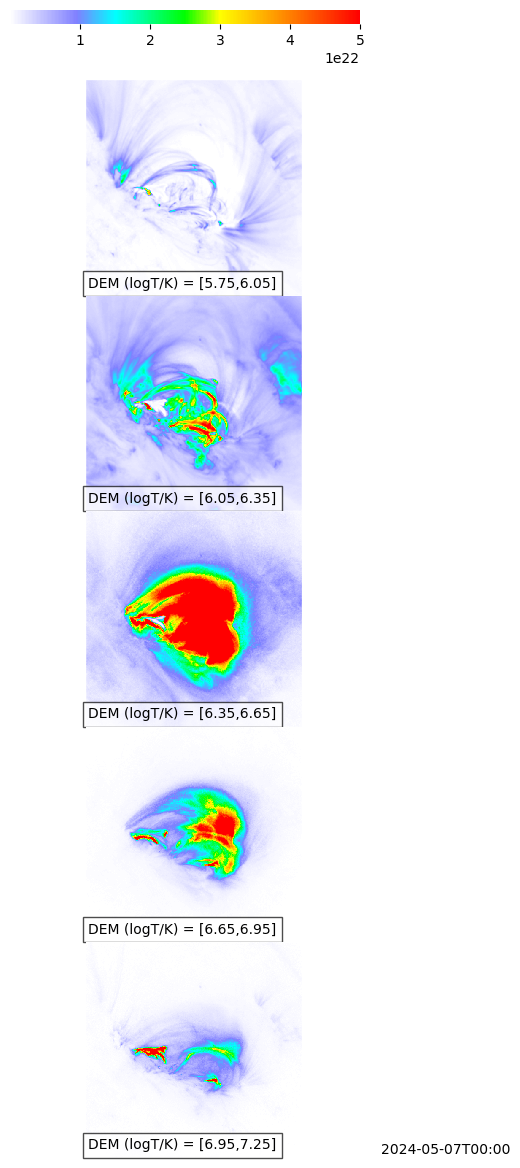

In [7]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(
    5, 1, figsize=(7,14),
    sharex=True, sharey=True
)

im1 = ax1.imshow(em1, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax1.text(5, 18, 'DEM (logT/K) = [5.75,6.05]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))
ax1.set_xticks([]); ax1.set_yticks([])

im2 = ax2.imshow(em2, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax2.set_xticks([]); ax2.set_yticks([])
ax2.text(5, 20, 'DEM (logT/K) = [6.05,6.35]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))

im3 = ax3.imshow(em3, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax3.set_xticks([]); ax3.set_yticks([])
ax3.text(5, 20, 'DEM (logT/K) = [6.35,6.65]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))

im4 = ax4.imshow(em4, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax4.set_xticks([]); ax4.set_yticks([])
ax4.text(5, 20, 'DEM (logT/K) = [6.65,6.95]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))

im5 = ax5.imshow(em5, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax5.text(5, 20, 'DEM (logT/K) = [6.95,7.25]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))
ax5.text(700, 10, '2024-05-07T00:00',
         color="black", size=10,
         )
ax5.set_xticks([]); ax5.set_yticks([])

plt.subplots_adjust(hspace=0)

cax = fig.add_axes([0.25, 0.92, 0.5, 0.01])  # [left, bottom, width, height]
cbar = fig.colorbar(im1, cax=cax, orientation='horizontal',shrink=0.3)
plt.subplots_adjust(hspace=0)


for ax in (ax1, ax2, ax3, ax4, ax5):
    for spine in ax.spines.values():
        spine.set_visible(False)


cbar.outline.set_visible(False)

plt.show()

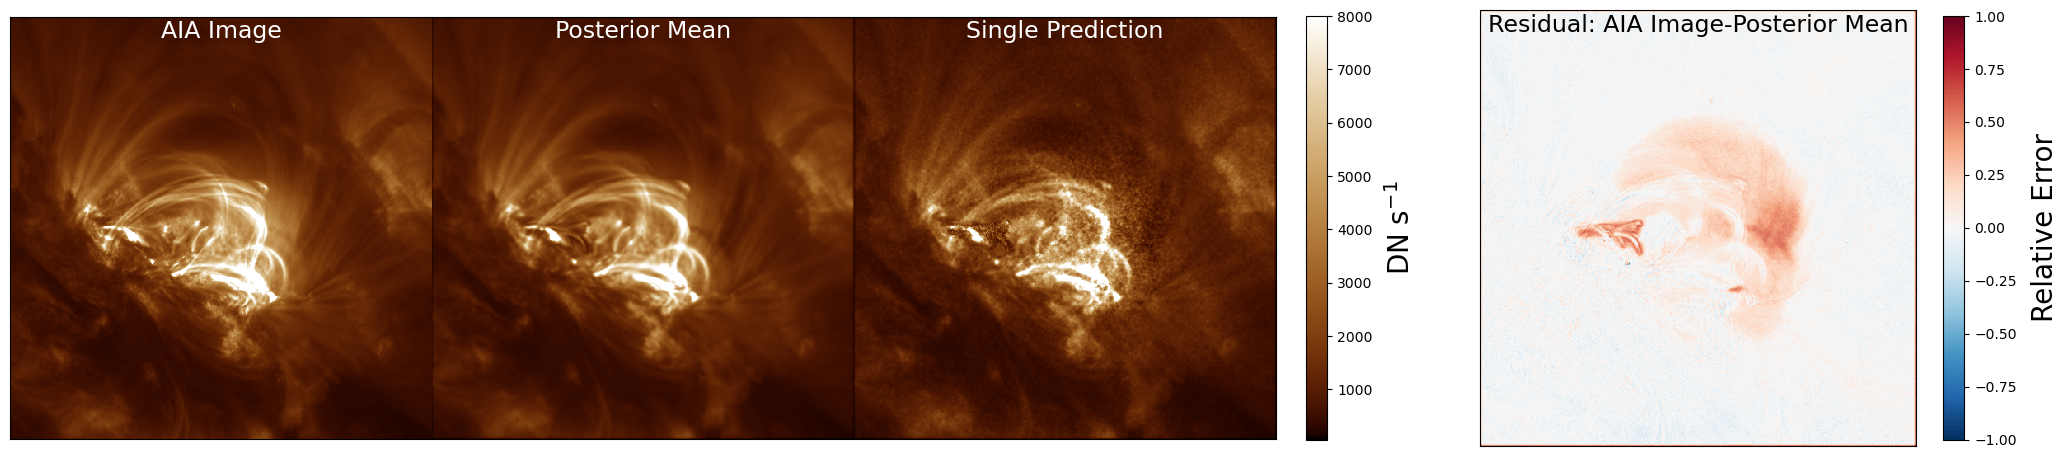

In [8]:
img1 = test_sample[:,:,3]
img2 = np.mean(img_list,0)[0,:,:,3]
img3 = img_list[0][0,:,:,3]
img4 = (img1 - img2)/img1

fig = plt.figure(figsize=(26,10))
gs = fig.add_gridspec(1, 4, wspace=-0.1)
ax1 = fig.add_subplot(gs[0, :3])
ax2 = fig.add_subplot(gs[0, 3])

# Left: three-panel combined
combined = np.concatenate([img1, img2, img3], axis=1)
im1 = ax1.imshow(combined,
                 cmap=matplotlib.colormaps['sdoaia193'],
                 vmax=8000,
                 interpolation='nearest', origin='lower')
ax1.set_xticks([])
ax1.set_yticks([])
cb1 = fig.colorbar(im1, ax=ax1, shrink=0.55, pad=0.02)
cb1.set_label(r'DN s$^{-1}$', size=20, labelpad=10)

h, w = img1.shape
ax1.text(w*0.5, h-26, 'AIA Image',          color='white', ha='center', size=17)
ax1.text(w*1.5, h-26, 'Posterior Mean',      color='white', ha='center', size=17)
ax1.text(w*2.5, h-26, 'Single Prediction',   color='white', ha='center', size=17)

# Right: residual map
im2 = ax2.imshow(img4,
                 cmap='RdBu_r',
                 vmin=-1, vmax=1,
                 interpolation='nearest', origin='lower')
ax2.set_xticks([])
ax2.set_yticks([])
cb2 = fig.colorbar(im2, ax=ax2, shrink=0.55)
cb2.set_label(r'Relative Error', size=20, labelpad=10)

ax2.text(w*0.5, h-26, 'Residual: AIA Image-Posterior Mean', color='black', ha='center', size=17)

plt.tight_layout()

plt.show()